In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; print('Urządzenie:', DEVICE)

Urządzenie: cuda


In [2]:
def gen(N, L):
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        # Losowanie 2 pozycji z zakresu od 9 do L (w Pythonie indeksy od 8 do L-1)
        p = np.random.choice(np.arange(8, L), 2, replace=False)
        mark[i, p, 0] = 1.0
        # Wartości wskazywane są przesunięte o 8 kroków wstecz (indeks p - 8)
        y[i, 0] = val[i, p - 8, 0].sum()
    x = np.concatenate([val, mark], axis=2)   # [N, L, 2]
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

# Podgląd jednego przykładu (weryfikacja wymagana w sprawozdaniu)
xx, yy = gen(1, 20)
poz = np.where(xx[0,:,1].cpu().numpy()==1)[0]
poz_wskaz = poz - 8

print(f'Pozycje znaczników (kroki t): {poz + 1} (indeksy wektora: {poz})')
print(f'Wskazywane pozycje (kroki t-8): {poz_wskaz + 1} (indeksy wektora: {poz_wskaz})')
print(f'Wartości wskazywane: {xx[0, poz_wskaz, 0].cpu().numpy().round(3)}')
print(f'Suma (cel): {float(yy[0,0])}')

Pozycje znaczników (kroki t): [13 18] (indeksy wektora: [12 17])
Wskazywane pozycje (kroki t-8): [ 5 10] (indeksy wektora: [4 9])
Wartości wskazywane: [0.424 0.383]
Suma (cel): 0.8070963025093079


In [3]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=64):
        super().__init__()
        self.rnn={'RNN':nn.RNN,'LSTM':nn.LSTM,'GRU':nn.GRU}[typ](2,hidden,batch_first=True)
        self.fc=nn.Linear(hidden,1)
    def forward(self,x):
        out,_=self.rnn(x); return self.fc(out[:,-1,:])

class ConvNet(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv1d(2,ch,3,padding=1,dilation=1),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=2,dilation=2),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=4,dilation=4),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=8,dilation=8),nn.ReLU(),
            nn.Conv1d(ch,ch,3,padding=16,dilation=16),nn.ReLU())
        self.fc=nn.Linear(ch,1)
    def forward(self,x):
        h=self.net(x.transpose(1,2)).mean(dim=2); return self.fc(h)

def licz_parametry(m): return sum(p.numel() for p in m.parameters())

In [4]:
def trenuj(model, L, epoki=30, N=4000, lr=5e-3, batch=128):
    model=model.to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=lr); Lf=nn.MSELoss()
    Xtr,Ytr=gen(N,L); Xte,Yte=gen(800,L)
    t0=time.time()
    for ep in range(epoki):
        model.train(); perm=torch.randperm(N)
        for i in range(0,N,batch):
            idx=perm[i:i+batch]; opt.zero_grad()
            Lf(model(Xtr[idx]),Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
    czas=time.time()-t0
    model.eval()
    with torch.no_grad(): mse=Lf(model(Xte),Yte).item()
    return mse, czas

In [5]:
L = 50
modele = {'SimpleRNN': RNNNet('RNN'), 'LSTM': RNNNet('LSTM'),
          'GRU': RNNNet('GRU'), 'Conv1D': ConvNet()}
wyniki_50 = {}
for nazwa, m in modele.items():
    mse, czas = trenuj(m, L)
    wyniki_50[nazwa] = {'mse': mse, 'czas': czas, 'params': licz_parametry(m)}
    print(f'{nazwa:10s}  MSE={mse:.4f}  czas={czas:4.1f}s  params={licz_parametry(m)}')

SimpleRNN   MSE=0.1608  czas= 3.2s  params=4417
LSTM        MSE=0.1651  czas= 2.6s  params=17473
GRU         MSE=0.0416  czas= 3.2s  params=13121
Conv1D      MSE=0.0005  czas= 3.5s  params=49921


In [6]:
L = 100
modele = {'SimpleRNN': RNNNet('RNN'), 'LSTM': RNNNet('LSTM'),
          'GRU': RNNNet('GRU'), 'Conv1D': ConvNet()}
wyniki_100 = {}
for nazwa, m in modele.items():
    mse, czas = trenuj(m, L)
    wyniki_100[nazwa] = {'mse': mse, 'czas': czas, 'params': licz_parametry(m)}
    print(f'{nazwa:10s}  MSE={mse:.4f}  czas={czas:4.1f}s  params={licz_parametry(m)}')

SimpleRNN   MSE=0.1607  czas= 2.1s  params=4417
LSTM        MSE=0.1708  czas= 2.8s  params=17473
GRU         MSE=0.1499  czas= 3.0s  params=13121
Conv1D      MSE=0.0042  czas= 3.1s  params=49921


In [7]:
import pandas as pd

data = []
for model in wyniki_50.keys():
    data.append({
        'Model': model,
        'Parametry': wyniki_50[model]['params'],
        'L=50 MSE': wyniki_50[model]['mse'],
        'L=50 Czas (s)': wyniki_50[model]['czas'],
        'L=100 MSE': wyniki_100[model]['mse'],
        'L=100 Czas (s)': wyniki_100[model]['czas']
    })

df_porownanie = pd.DataFrame(data)
display(df_porownanie)

,Model,Parametry,L=50 MSE,L=50 Czas (s),L=100 MSE,L=100 Czas (s)
0,SimpleRNN,4417,0.160828,3.166063,0.160710,2.149104
1,LSTM,17473,0.165124,2.557088,0.170772,2.809983
2,GRU,13121,0.041601,3.218895,0.149930,3.024018
3,Conv1D,49921,0.000540,3.501685,0.004195,3.071477


In [8]:
for L in [50, 100]:
    mse,_ = trenuj(RNNNet('RNN'), L); print(f'RNN  L={L}: {mse:.4f}')
    mse,_ = trenuj(RNNNet('GRU'), L); print(f'GRU  L={L}: {mse:.4f}')

RNN  L=50: 0.1533
GRU  L=50: 0.0638
RNN  L=100: 0.1717
GRU  L=100: 0.1453


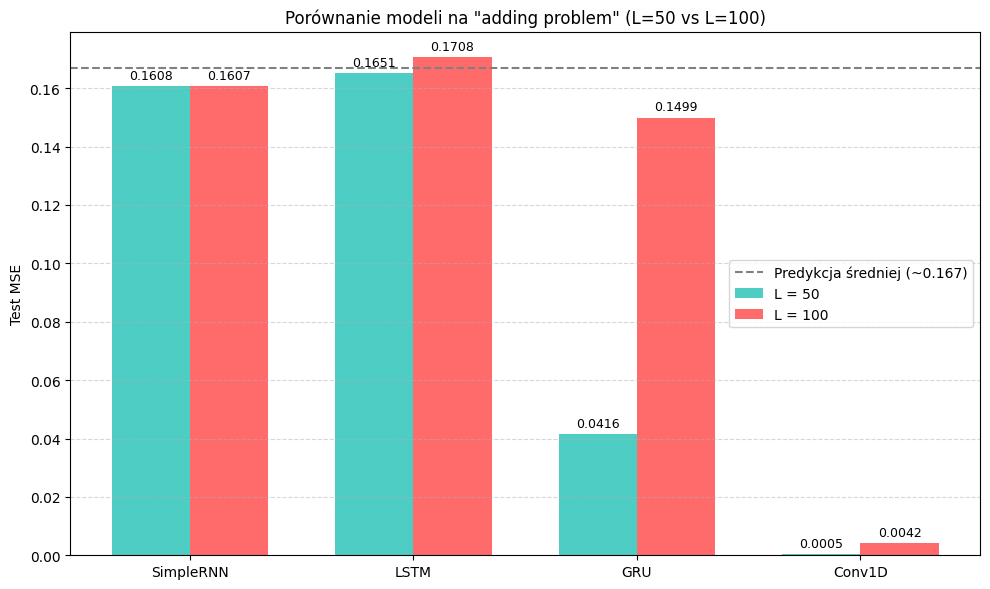

In [9]:
import matplotlib.pyplot as plt
import numpy as np

modele_names = list(wyniki_50.keys())
mse_50 = [wyniki_50[m]['mse'] for m in modele_names]
mse_100 = [wyniki_100[m]['mse'] for m in modele_names]

x = np.arange(len(modele_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width/2, mse_50, width, label='L = 50', color='#4ecdc4')
rects2 = ax.bar(x + width/2, mse_100, width, label='L = 100', color='#ff6b6b')

ax.axhline(0.167, ls='--', color='gray', label='Predykcja średniej (~0.167)')

ax.set_ylabel('Test MSE')
ax.set_title('Porównanie modeli na "adding problem" (L=50 vs L=100)')
ax.set_xticks(x)
ax.set_xticklabels(modele_names)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

Hidden Size:  16 | Params:    977 | Test MSE: 0.168565
Hidden Size:  32 | Params:   3489 | Test MSE: 0.176679
Hidden Size:  64 | Params:  13121 | Test MSE: 0.169651
Hidden Size: 128 | Params:  50817 | Test MSE: 0.162851

Badanie pola recepcyjnego dla Conv1D (L=100):
Max Dilation:  4 | Receptive Field:  15 | Params:  25217 | Test MSE: 0.168313
Max Dilation:  8 | Receptive Field:  31 | Params:  37569 | Test MSE: 0.133258
Max Dilation: 16 | Receptive Field:  63 | Params:  49921 | Test MSE: 0.007664
Max Dilation: 32 | Receptive Field: 127 | Params:  62273 | Test MSE: 0.003039


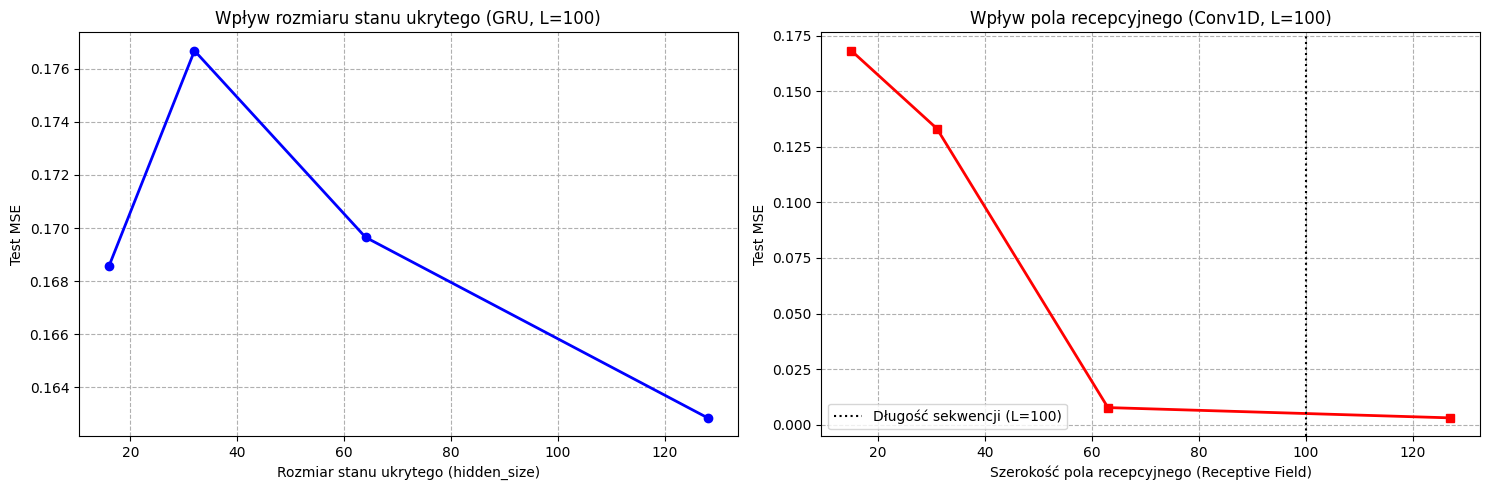

In [10]:
import matplotlib.pyplot as plt

hidden_sizes = [16, 32, 64, 128]
results_gru_hidden = {}

for h in hidden_sizes:
    model_gru = RNNNet('GRU', hidden=h)
    mse, czas = trenuj(model_gru, L=100, epoki=25)
    results_gru_hidden[h] = {'mse': mse, 'params': licz_parametry(model_gru)}
    print(f"Hidden Size: {h:3d} | Params: {results_gru_hidden[h]['params']:6d} | Test MSE: {mse:.6f}")

class VariableConvNet(nn.Module):
    def __init__(self, max_dilation=16, ch=64):
        super().__init__()
        layers = []
        in_ch = 2
        dilation = 1
        while dilation <= max_dilation:
            layers.append(nn.Conv1d(in_ch, ch, 3, padding=dilation, dilation=dilation))
            layers.append(nn.ReLU())
            in_ch = ch
            dilation *= 2
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(ch, 1)
        self.max_dilation = max_dilation

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)
dilations = [4, 8, 16, 32]
results_conv_rf = {}

print("\nBadanie pola recepcyjnego dla Conv1D (L=100):")
for d in dilations:
    model_conv = VariableConvNet(max_dilation=d)
    mse, czas = trenuj(model_conv, L=100, epoki=25)
    rf = 1 + sum(2 * (2**i) for i in range(int(np.log2(d)) + 1))
    results_conv_rf[rf] = {'mse': mse, 'params': licz_parametry(model_conv), 'max_dil': d}
    print(f"Max Dilation: {d:2d} | Receptive Field: {rf:3d} | Params: {results_conv_rf[rf]['params']:6d} | Test MSE: {mse:.6f}")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(list(results_gru_hidden.keys()), [v['mse'] for v in results_gru_hidden.values()], marker='o', color='b', linewidth=2)
ax1.set_title("Wpływ rozmiaru stanu ukrytego (GRU, L=100)")
ax1.set_xlabel("Rozmiar stanu ukrytego (hidden_size)")
ax1.set_ylabel("Test MSE")
ax1.grid(True, linestyle='--')


ax2.plot(list(results_conv_rf.keys()), [v['mse'] for v in results_conv_rf.values()], marker='s', color='r', linewidth=2)
ax2.axvline(100, ls=':', color='black', label='Długość sekwencji (L=100)')
ax2.set_title("Wpływ pola recepcyjnego (Conv1D, L=100)")
ax2.set_xlabel("Szerokość pola recepcyjnego (Receptive Field)")
ax2.set_ylabel("Test MSE")
ax2.legend()
ax2.grid(True, linestyle='--')

plt.tight_layout()
plt.show()